In [1]:
# import libraries
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge

from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')

In [2]:
# generate synthetic data
np.random.seed(0)

X = np.random.rand(100,1)
y = 2*X + 1 + 0.1 * np.random.rand(100,1)

# split
X_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [6]:
# define alphas/lambdas

alphas = np.logspace(-2,0.5,200)

lasso_coefs = []
ridge_coefs = []
lr_coefs = []

for alpha in alphas:
    #lasso
    lasso = Lasso(alpha=alpha)
    lasso.fit(X_train,y_train)
    lasso_coefs.append(lasso.coef_[0])

    #ridge
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train,y_train)
    ridge_coefs.append(ridge.coef_[0])

    #normal linear regression without regularization
    lr = Ridge(alpha=alpha)
    lr.fit(X_train,y_train)
    lr_coefs.append(lr.coef_[0])

# do the prediction
y_lasso = lasso.predict(x_test)
y_ridge = ridge.predict(x_test)
y_lr = lr.predict(x_test)

# calculate the MSE
mse_lasso = mean_squared_error(y_test,y_lasso)
mse_ridge = mean_squared_error(y_test,y_ridge)
mse_lr = mean_squared_error(y_test,y_lr)


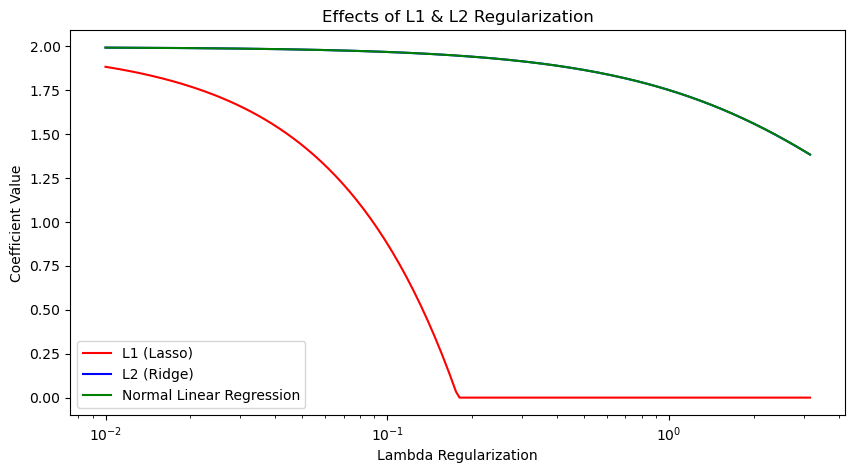

In [8]:
# plot
plt.figure(figsize=(10,5))
plt.plot(alphas,lasso_coefs,label='L1 (Lasso)', color = 'r')
plt.plot(alphas,ridge_coefs,label='L2 (Ridge)', color = 'b')
plt.plot(alphas,lr_coefs,label='Normal Linear Regression', color = 'g')

# set scale
plt.xscale('log')
plt.axis('tight')

# set labels
plt.xlabel('Lambda Regularization')
plt.ylabel('Coefficient Value')
plt.title('Effects of L1 & L2 Regularization')
plt.legend()

plt.show()

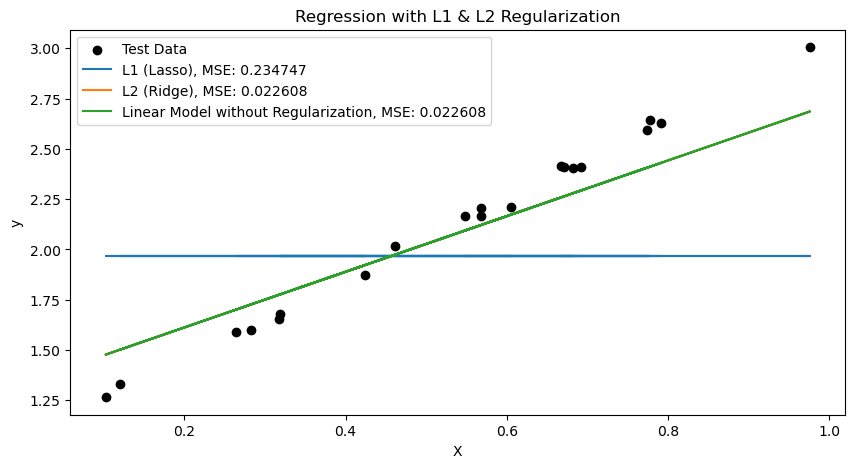

In [7]:
# Plot prediction for each model
plt.figure(figsize=(10, 5))
# Plot the data point
plt.scatter(x_test, y_test, label='Test Data', color='black')
# Plot line
plt.plot(x_test, y_lasso, label=f'L1 (Lasso), MSE: {mse_lasso:3f}')
plt.plot(x_test, y_ridge, label=f'L2 (Ridge), MSE: {mse_ridge:3f}')
plt.plot(x_test, y_lr, label=f'Linear Model without Regularization, MSE: {mse_lr:3f}')
# For label
plt.xlabel('X')
plt.ylabel('y')
plt.title('Regression with L1 & L2 Regularization')
plt.legend()
plt.show()

| Column name | Description |
| --- | --- |
CRIM | per capita crime rate by town
ZN | proportion of residential land zoned for lots over 25,000 sq.ft.
INDUS | proportion of non-retail business acres per town
CHAS | Charles River dummy variable (= 1 if tract bounds river; 0 otherwise) NOX | nitric oxides concentration (parts per 10 million)
RM | average number of rooms per dwelling 
AGE | proportion of owner-occupied units built prior to 1940 DIS | weighted distances to five Boston employment centers RAD | index of accessibility to radial highways
TAX | full-value property-tax rate per $10,000 
PTRATIO | pupil-teacher ratio by town
B | 1000(Bk - 0.63)^2 where Bk is the proportion of Black people by town LSTAT | % lower status of the population
MEDV | Median value of owner-occupied homes in $1000’s

In [9]:
# using the real dataset
boston = pd.read_csv('Dataset/boston.csv')
boston

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48,22.0


In [10]:
# define the X and y
X = boston.drop(['MEDV'],axis=1 )
y = boston['MEDV']

In [11]:
# feature selection
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [30]:
# ridge regression (L2)
hyperparam_c = [100000,10000,1000,10,1,0.1,0.01,0.001]
training_mse = []
testing_mse = []
score = 0

for i in hyperparam_c:
    ridge = Ridge(alpha=i)
    ridge.fit(X_train,y_train)

    y_predict_train = ridge.predict(X_train)
    training_mse.append(mean_squared_error(y_train,y_predict_train))

    y_predict_test = ridge.predict(X_test)
    mse_score = mean_squared_error(y_test,y_predict_test)
    testing_mse.append(mse_score)

    if score > -mse_score:
        score = mse_score
        best_c = i

In [13]:
# create dataframe
df_c = pd.DataFrame(
    {
        'hyperparam_c': hyperparam_c,
        'training_mse': training_mse,
        'testing_mse': testing_mse
    }
)
df_c.head()

,hyperparam_c,training_mse,testing_mse
0,100000.0,57.597498,43.771011
1,10000.0,39.687400,30.951028
2,1000.0,29.038567,24.695930
3,10.0,22.435172,24.648348
4,1.0,21.824118,24.477191


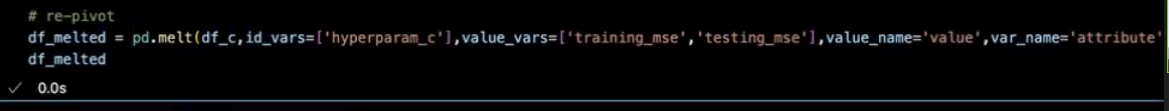

In [17]:
# re-pivot
df_melted = pd.melt(
    df_c, 
    id_vars=['hyperparam_c'],
    value_vars=['training_mse', 'testing_mse'],
    value_name='value',
    var_name='attribute'
)
df_melted['x_axis'] = df_melted.groupby('attribute')['hyperparam_c'].rank(method='first',ascending=False)
# df_melted

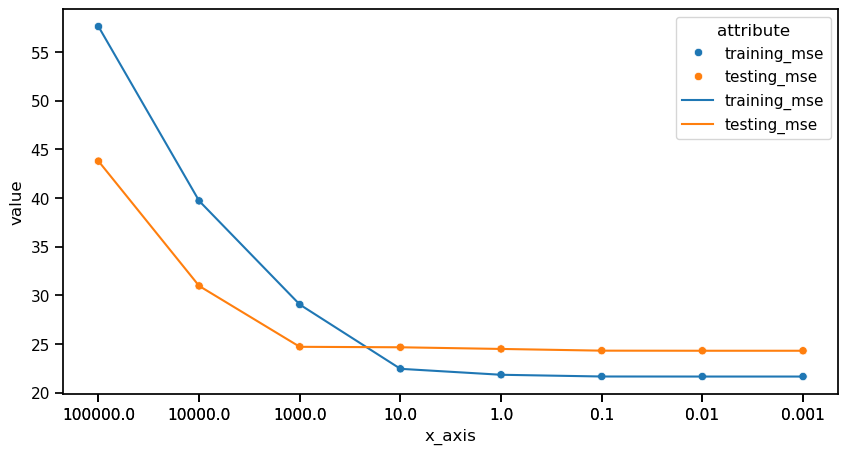

In [18]:
# plot
plt.figure(figsize = (10,5))
sns.set_context('notebook', font_scale=1)
ax = sns.scatterplot(
    data=df_melted,
    x='x_axis',
    y='value',
    hue='attribute'
)
sns.lineplot(
    data=df_melted,
    x='x_axis',
    y='value',
    hue='attribute'
)
ax.set_xticks(df_melted['x_axis'], df_melted['hyperparam_c'])

In [31]:
print('best_c:', best_c)
print('mse:', score)

best_c: 0.001
mse: 24.291177851311268


In [32]:
# we got the best_c ->best lambda, now let's see the coefficient for each feature
ridgereg = Ridge(alpha=best_c)
ridgereg.fit(X_train,y_train)
y_reg_train = ridgereg.predict(X_train)
y_reg_test = ridgereg.predict(X_test)

In [33]:
coef_ridgereg = pd.DataFrame(
    {'feature_names':list(X),
     'feature coef':ridgereg.coef_}
)
coef_ridgereg

,feature_names,feature coef
0,CRIM,-0.113049
1,ZN,0.030114
2,INDUS,0.040322
3,CHAS,2.784077
4,NOX,-17.188839
5,RM,4.438913
6,AGE,-0.006307
7,DIS,-1.447668
8,RAD,0.262404
9,TAX,-0.010648
